# Feature Store with Lineage — Results Notebook
Telco churn · Feast (offline Parquet/DuckDB + online Redis) · skew detection · lineage · fairness.
Run the pipeline first (`docker compose up --build` or `make local`).

In [1]:
import os, sys, json
sys.path.insert(0, os.path.abspath('..')); os.chdir(os.path.abspath('..'))
os.environ.setdefault('FEAST_ONLINE', 'redis'); os.environ.setdefault('REDIS_CONNECTION', 'redis:6379')
import pandas as pd, numpy as np, matplotlib.pyplot as plt
import common as C, skew_detection as S
store = C.get_store()
print('online backend:', C.online_backend())

online backend: redis


## 1. Registry & governance metadata

In [2]:
rows = [dict(view=fv.name, owner=fv.owner, n_features=len(fv.features), sensitive=fv.tags.get('sensitive'), PII=fv.tags.get('PII'), fairness_audit=fv.tags.get('fairness_audit'), source_table=fv.tags.get('source_table')) for fv in store.list_feature_views()]
pd.DataFrame(rows)

,view,owner,n_features,sensitive,PII,fairness_audit,source_table
0,customer_demographics,Retention-Data-Team,4,demographic,none,required,raw_telco_customer
1,customer_services,Retention-Data-Team,10,none,none,not_required,raw_telco_services
2,customer_billing,Retention-Data-Team,7,financial,none,proxy_check,raw_telco_billing


## 2. Offline (point-in-time) vs online features for the same customers

In [3]:
svc = store.get_feature_service(C.FEATURE_SERVICE)
labels = pd.read_parquet(C.OFFLINE_DIR/'labels.parquet').head(5)
off = store.get_historical_features(entity_df=labels[['customer_id','event_timestamp']], features=svc).to_df()
on = store.get_online_features(features=svc, entity_rows=[{'customer_id': c} for c in labels.customer_id]).to_df()
print('OFFLINE'); display(off.iloc[:, :8]); print('ONLINE'); display(on.iloc[:, :8])

OFFLINE


,customer_id,event_timestamp,gender,senior_citizen,partner,dependents,phone_service,multiple_lines
0,7795-CFOCW,2025-07-01 00:00:00+00:00,Male,0,No,No,No,No phone service
1,5575-GNVDE,2025-07-01 00:00:00+00:00,Male,0,No,No,Yes,No
2,9237-HQITU,2025-07-01 00:00:00+00:00,Female,0,No,No,Yes,No
3,3668-QPYBK,2025-07-01 00:00:00+00:00,Male,0,No,No,Yes,No
4,7590-VHVEG,2025-07-01 00:00:00+00:00,Female,0,Yes,No,No,No phone service


ONLINE


,customer_id,gender,partner,dependents,senior_citizen,streaming_tv,internet_service,device_protection
0,7590-VHVEG,Female,Yes,No,0,No,DSL,No
1,5575-GNVDE,Male,No,No,0,No,DSL,Yes
2,3668-QPYBK,Male,No,No,0,No,DSL,No
3,7795-CFOCW,Male,No,No,0,No,DSL,Yes
4,9237-HQITU,Female,No,No,0,No,Fiber optic,No


## 3. Model performance, latency and online/offline parity

In [4]:
m = json.load(open(C.ARTIFACT_DIR/'metrics.json'))
pd.DataFrame({'all features': m['all_features'], 'without sensitive': m['without_sensitive']}).T

,roc_auc,f1,recall,precision,threshold
all features,0.835205,0.613076,0.764706,0.511628,0.5
without sensitive,0.837366,0.613419,0.770053,0.509735,0.5


In [5]:
print(json.dumps({k: m[k] for k in ['online_latency_ms','online_offline_parity']}, indent=2))

{
  "online_latency_ms": {
    "backend": "redis",
    "single_p50": 20.181792499997186,
    "single_p95": 32.4145673000032,
    "batch100_p50": 24.475830500001905
  },
  "online_offline_parity": {
    "entities": 1409,
    "mismatching_features": {},
    "pass": true
  }
}


## 4. Fairness across demographic slices

In [6]:
fr = json.load(open(C.ARTIFACT_DIR/'fairness_report.json'))
tab = pd.DataFrame({a: {'DP diff': r['demographic_parity_diff'], 'DI ratio': r['disparate_impact_ratio'], 'EO diff': r['equal_opportunity_diff']} for a, r in fr['with_sensitive'].items()}).T
tab.round(3)

,DP diff,DI ratio,EO diff
gender,0.003,0.991,0.038
senior_citizen,0.314,0.524,0.181
partner,0.216,0.569,0.139
dependents,0.251,0.465,0.132


In [7]:
rows=[]
for a, r in fr['with_sensitive'].items():
    for g, v in r['groups'].items(): rows.append(dict(attribute=a, group=g, n=v['n'], base_rate=v['base_rate'], selection_rate=v['selection_rate'], recall=v['tpr_recall'], fpr=v['fpr'], auc=v['roc_auc']))
pd.DataFrame(rows).round(3)

,attribute,group,n,base_rate,selection_rate,recall,fpr,auc
0,gender,Female,733,0.252,0.398,0.784,0.268,0.837
1,gender,Male,676,0.280,0.395,0.746,0.259,0.835
2,senior_citizen,0,1180,0.246,0.346,0.724,0.222,0.844
3,senior_citizen,1,229,0.367,0.659,0.905,0.517,0.781
4,partner,No,731,0.326,0.501,0.815,0.349,0.816
5,partner,Yes,678,0.201,0.285,0.676,0.186,0.841
6,dependents,No,1001,0.304,0.470,0.789,0.330,0.808
7,dependents,Yes,408,0.172,0.218,0.657,0.127,0.879


## 5. Skew detection — three scenarios
`clean` = online store vs training (control); `schema` = type/encoding skew; `drift` = value/distribution skew.

In [8]:
reports = S.run('all', n=1200)
print({r['scenario']: r['overall_status'] for r in reports})


=== Skew report [clean_online_vs_train]  ->  PASS  (baseline n=5634, live n=1200) ===
feature               kind             PSI  level    test                   stat   p-value  status
gender                categorical   0.0043  stable   chi2_contingency      4.095  4.30e-02  PASS
senior_citizen        categorical   0.0000  stable   chi2_contingency      0.000  1.00e+00  PASS
partner               categorical   0.0001  stable   chi2_contingency      0.086  7.70e-01  PASS
dependents            categorical   0.0007  stable   chi2_contingency      0.633  4.26e-01  PASS
phone_service         categorical   0.0001  stable   chi2_contingency      0.110  7.41e-01  PASS
multiple_lines        categorical   0.0018  stable   chi2_contingency      1.748  4.17e-01  PASS
internet_service      categorical   0.0057  stable   chi2_contingency      5.464  6.51e-02  PASS
online_security       categorical   0.0056  stable   chi2_contingency      5.387  6.77e-02  PASS
online_backup         categorical   0.

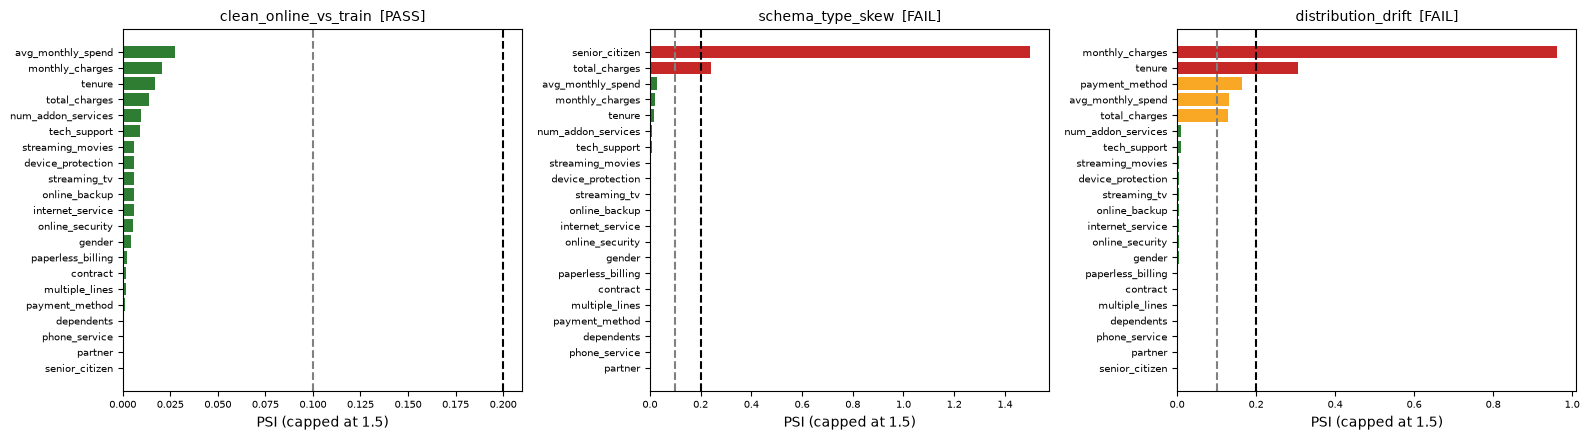

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=False)
for ax, r in zip(axes, reports):
    psi = pd.Series({f: min(v['psi'], 1.5) for f, v in r['features'].items()}).sort_values()
    colors = ['#2e7d32' if x < .1 else '#f9a825' if x <= .2 else '#c62828' for x in psi]
    ax.barh(psi.index, psi.values, color=colors); ax.axvline(.1, ls='--', c='grey'); ax.axvline(.2, ls='--', c='k')
    ax.set_title(f"{r['scenario']}  [{r['overall_status']}]", fontsize=10); ax.set_xlabel('PSI (capped at 1.5)'); ax.tick_params(labelsize=7)
plt.tight_layout(); plt.savefig(C.ARTIFACT_DIR/'psi_by_scenario.png', dpi=150); plt.show()

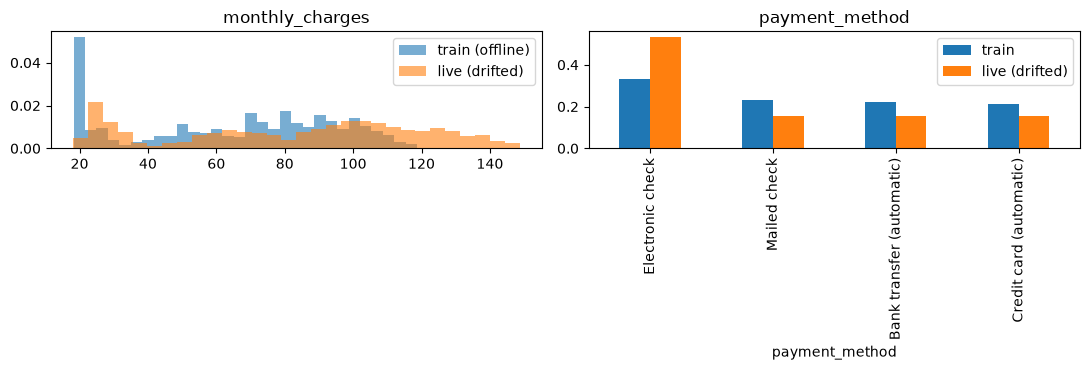

In [10]:
base, live = S.load_baseline(), S.fetch_online(1200); drift = S.inject_drift(live)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(base.monthly_charges, bins=30, alpha=.6, density=True, label='train (offline)'); ax[0].hist(drift.monthly_charges, bins=30, alpha=.6, density=True, label='live (drifted)'); ax[0].set_title('monthly_charges'); ax[0].legend()
pd.concat([base.payment_method.value_counts(normalize=True).rename('train'), drift.payment_method.value_counts(normalize=True).rename('live (drifted)')], axis=1).plot.bar(ax=ax[1], title='payment_method'); plt.tight_layout(); plt.savefig(C.ARTIFACT_DIR/'drift_distributions.png', dpi=150); plt.show()

In [11]:
print(json.dumps(reports[1]['schema_issues'], indent=1))

[
 {
  "feature": "senior_citizen",
  "issue": "dtype_mismatch",
  "expected": "int64",
  "actual": "object",
  "unparseable_values": 1200,
  "examples": [
   "No",
   "Yes"
  ]
 },
 {
  "feature": "total_charges",
  "issue": "dtype_mismatch",
  "expected": "float64",
  "actual": "object",
  "unparseable_values": 130,
  "examples": [
   "<space>"
  ]
 }
]


## 7. Live Redis benchmark and scale test (`benchmark_and_scale.py`)

In [12]:
b = json.load(open(C.ARTIFACT_DIR/'benchmark_metrics.json'))
print(json.dumps(b['environment'], indent=1))
sl = b['serving_latency']
pd.DataFrame({k: v for k, v in sl.items() if k.startswith(('single','batch','raw'))}).T[['p50','p95','p99','mean','n']]

{
 "redis_url": "redis://localhost:6379/0",
 "redis_version": "7.0.15",
 "redis_os": "Linux 6.18.44-fc-v153 x86_64",
 "in_docker_container": false,
 "python": "3.12.3",
 "cpu_count": 1,
 "machine": "x86_64",
 "timestamp_utc": "2026-10-24T15:52:12+00:00"
}


,p50,p95,p99,mean,n
single_entity_ms,3.387,5.684,6.449,3.773,1000.0
batch_1_ms,5.187,5.659,5.825,4.502,60.0
batch_10_ms,5.193,7.135,8.618,5.435,60.0
batch_100_ms,25.132,48.929,85.771,31.480,60.0
batch_1000_ms,362.547,537.591,543.649,380.967,20.0
raw_redis_ping_ms,0.058,0.109,0.139,0.062,2000.0


In [13]:
sc = pd.DataFrame([{'entities': s['entities'], 'records': s['records_materialized'], 'seconds': s['materialize_seconds'], 'records_per_sec': s['throughput_records_per_sec'], 'redis_MB': s['redis_used_memory_mb'], 'parquet_MB': s['parquet_bytes_total']/1e6, 'single_p50_ms': s['online_latency']['single_entity_ms']['p50'], 'single_p99_ms': s['online_latency']['single_entity_ms']['p99'], 'batch100_p50_ms': s['online_latency']['batch_100_ms']['p50']} for s in b['scale_test']])
sc.round(2)

,entities,records,seconds,records_per_sec,redis_MB,parquet_MB,single_p50_ms,single_p99_ms,batch100_p50_ms
0,7043,21129,2.36,8953,4.1,0.47,8.27,13.27,41.66
1,35215,105645,11.89,8885,20.7,1.86,8.50,14.11,32.06
2,105645,316935,35.31,8976,61.7,4.96,7.78,14.24,35.15
3,211290,633870,63.41,9996,123.4,9.37,7.89,13.91,32.20


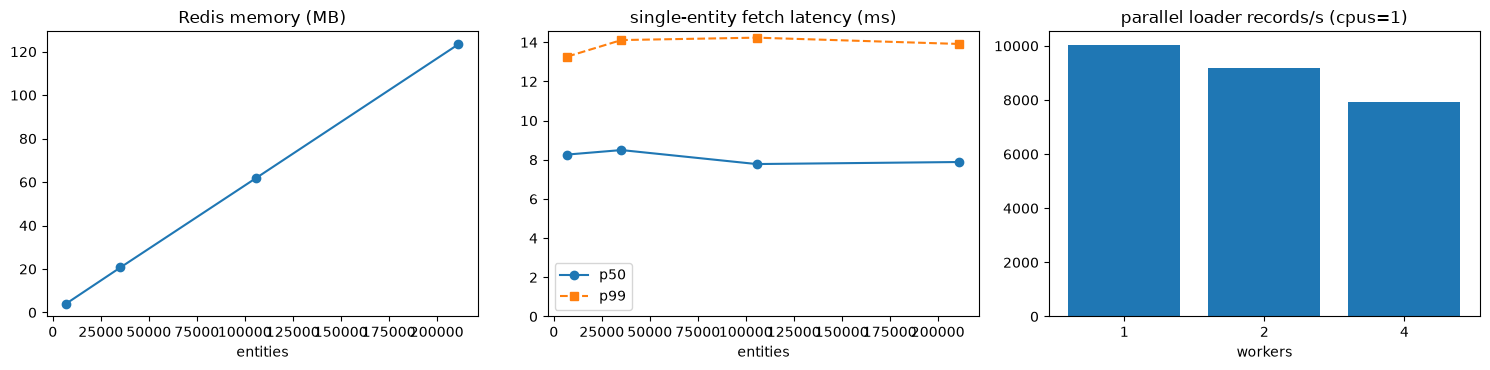

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].plot(sc.entities, sc.redis_MB, 'o-'); ax[0].set_title('Redis memory (MB)'); ax[0].set_xlabel('entities')
ax[1].plot(sc.entities, sc.single_p50_ms, 'o-', label='p50'); ax[1].plot(sc.entities, sc.single_p99_ms, 's--', label='p99'); ax[1].set_title('single-entity fetch latency (ms)'); ax[1].legend(); ax[1].set_ylim(0, None); ax[1].set_xlabel('entities')
pl = pd.DataFrame(b['parallel_loading']['runs']); ax[2].bar(pl.workers.astype(str), pl.throughput_records_per_sec); ax[2].set_title(f"parallel loader records/s (cpus={b['parallel_loading']['cpu_count']})"); ax[2].set_xlabel('workers')
plt.tight_layout(); plt.savefig(C.ARTIFACT_DIR/'benchmark_scale.png', dpi=150); plt.show()

## 8. Fairness mitigation (`fairness_mitigation.py`)

In [15]:
fm = json.load(open(C.ARTIFACT_DIR/'fairness_mitigated_report.json'))
t = pd.DataFrame(fm['comparison_table']).set_index('method')
t[['threshold_1','selection_rate_ref','selection_rate_target','fpr_ref','fpr_target','disparate_impact_ratio','equal_opportunity_diff','average_odds_difference','roc_auc_effective','roc_auc_degradation_vs_baseline','f1','recall','di_95ci']]

,threshold_1,selection_rate_ref,selection_rate_target,fpr_ref,fpr_target,disparate_impact_ratio,equal_opportunity_diff,average_odds_difference,roc_auc_effective,roc_auc_degradation_vs_baseline,f1,recall,di_95ci
method,,,,,,,,,,,,,
baseline_xgboost,0.50,0.346,0.668,0.226,0.531,0.518,0.191,0.248,0.8310,0.0000,0.605,0.757,"[0.459, 0.582]"
threshold_equalized_odds,0.73,0.346,0.428,0.226,0.276,0.808,0.023,0.037,0.8246,0.0064,0.602,0.709,"[0.695, 0.975]"
threshold_demographic_parity,0.81,0.346,0.332,0.226,0.214,0.960,0.178,0.095,0.8184,0.0126,0.587,0.674,"[0.769, 0.995]"
reweighing,0.50,0.357,0.524,0.236,0.372,0.681,0.058,0.097,0.8286,0.0024,0.605,0.741,"[0.598, 0.801]"
reweighing+threshold_eo,0.60,0.357,0.432,0.236,0.283,0.825,0.037,0.042,0.8241,0.0070,0.602,0.719,"[0.706, 0.982]"


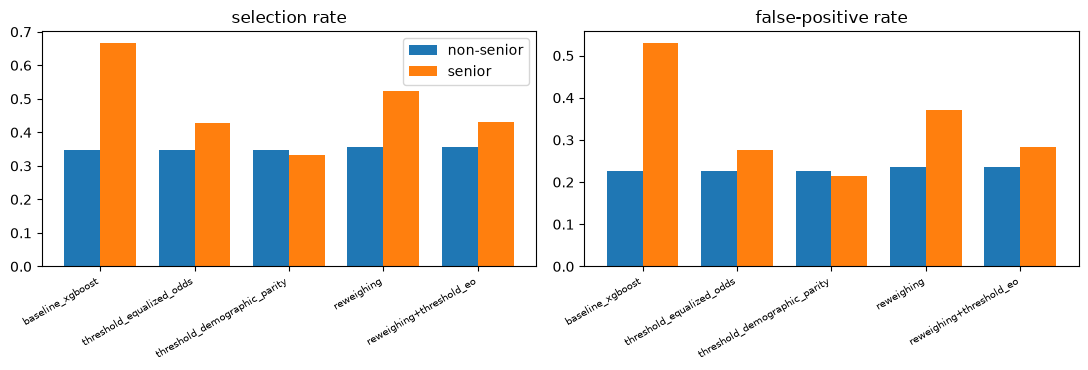

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8)); x = np.arange(len(t)); w = .38
ax[0].bar(x - w/2, t.selection_rate_ref, w, label='non-senior'); ax[0].bar(x + w/2, t.selection_rate_target, w, label='senior'); ax[0].set_xticks(x); ax[0].set_xticklabels(t.index, rotation=30, ha='right', fontsize=7); ax[0].set_title('selection rate'); ax[0].legend()
ax[1].bar(x - w/2, t.fpr_ref, w, label='non-senior'); ax[1].bar(x + w/2, t.fpr_target, w, label='senior'); ax[1].set_xticks(x); ax[1].set_xticklabels(t.index, rotation=30, ha='right', fontsize=7); ax[1].set_title('false-positive rate')
plt.tight_layout(); plt.savefig(C.ARTIFACT_DIR/'fairness_mitigation.png', dpi=150); plt.show()

## 9. Lineage dictionary (generated from the live Feast registry)

In [17]:
pd.read_json('docs/lineage_dictionary.json')[['feature','source_table','source_columns','transformation','owner','sensitive_tag']]

,feature,source_table,source_columns,transformation,owner,sensitive_tag
0,gender,raw_telco_customer,[gender],Copied as-is,Retention-Data-Team,demographic
1,senior_citizen,raw_telco_customer,[SeniorCitizen],CAST to BIGINT (0/1),Retention-Data-Team,demographic
2,partner,raw_telco_customer,[Partner],Copied as-is,Retention-Data-Team,demographic
3,dependents,raw_telco_customer,[Dependents],Copied as-is,Retention-Data-Team,demographic
4,phone_service,raw_telco_services,[PhoneService],Copied as-is,Retention-Data-Team,none
5,multiple_lines,raw_telco_services,[MultipleLines],Copied as-is,Retention-Data-Team,none
6,internet_service,raw_telco_services,[InternetService],Copied as-is,Retention-Data-Team,none
7,online_security,raw_telco_services,[OnlineSecurity],Copied as-is,Retention-Data-Team,none
8,online_backup,raw_telco_services,[OnlineBackup],Copied as-is,Retention-Data-Team,none
9,device_protection,raw_telco_services,[DeviceProtection],Copied as-is,Retention-Data-Team,none


In [18]:
print(open('docs/lineage.mmd').read()[:600], '...')  # full Mermaid graph in docs/lineage.md

flowchart LR
  subgraph SRC["Raw sources (DuckDB data/telco.duckdb)"]
    CSV[("IBM Telco CSV<br/>public dataset")]
    RC[("raw_telco_customer")]
    RS[("raw_telco_services")]
    RB[("raw_telco_billing")]
  end
  CSV -- "ingest_data.py<br/>split by column group" --> RC & RS & RB
  subgraph ETL["ETL / transformation layer (DuckDB SQL)"]
    T1["clean + CAST<br/>snapshot event_timestamp"]
    T2["num_addon_services<br/>= count of 'Yes' add-ons"]
    T3["total_charges: blank->0.0<br/>avg_monthly_spend = total/tenure"]
  end
  RC --> T1
  RS --> T2
  RB --> T3
  subgraph OFF["Feast OFFLINE stor ...
